# Đánh giá và so sánh 3 mô hình: Autoencoder, Isolation Forest, VAE

**Notebook này làm gì:** đọc kết quả đã lưu của 3 notebook mô hình rồi lập **bảng so sánh Precision / Recall / F1 / ROC-AUC / PR-AUC** (task Tuần 3 trong checklist).
Không huấn luyện lại gì cả, chạy vài phút.

**Cách chạy trên Kaggle:** bấm *Add Input* và thêm output của 3 notebook `mode-aue`, `iso-model`, `02c-vae-1`.
Notebook tự tìm các file `*_tong_hop.csv`, `*_theo_loai.csv`, `*_chi_tiet.csv`, `*_huan_luyen.csv` và `scores/*_devN.npz`.

Notebook gộp 3 task: **so sánh 3 mô hình** (mục 2–5), **biểu đồ phân phối lỗi tái tạo có ngưỡng** (mục 6), **confusion matrix và phân tích lỗi** (mục 7–8).

| Chỉ số | Nghĩa | Lấy từ đâu |
| --- | --- | --- |
| **Precision** | Khi báo "tấn công", bao nhiêu % là đúng (quy về tỷ lệ tấn công 5%) | `*_tong_hop.csv` |
| **Recall** | Trong 100 dòng tấn công, bắt được bao nhiêu (trung bình các loại tấn công) | `*_tong_hop.csv` |
| **F1** | Điểm gộp Precision và Recall, 0 đến 1 | `*_tong_hop.csv` |
| **ROC-AUC** | Điểm bất thường tách tấn công khỏi benign tốt đến đâu, **không phụ thuộc ngưỡng**. 0,5 = đoán bừa, 1 = tách hoàn toàn | tính lại từ điểm số |
| **PR-AUC** | Giống ROC-AUC nhưng nhìn theo Precision–Recall, khắt khe hơn khi tấn công hiếm. Tính ở tỷ lệ tấn công 5% | tính lại từ điểm số |

Mọi chỉ số đều tính trên **phần test** (benign test + nửa sau theo thời gian của mỗi loại tấn công), giống hệt 3 notebook mô hình.

## 1. Cấu hình và tìm file

In [1]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

MODELS = {"ae": "Autoencoder", "iforest": "Isolation Forest", "vae": "VAE"}
RULE = "f1_opt"          # quy tắc ngưỡng chính (giống mục VI của 3 notebook)
RULE_FAIR = "p99"        # quy tắc chỉ dùng benign, để so sánh công bằng không dùng nhãn
PI = 0.05                # tỷ lệ tấn công giả định 5%
TCP_UDP = ["gafgyt_tcp", "gafgyt_udp"]
DEV_PLOT = 1             # thiết bị dùng để vẽ đường ROC / PR
SEARCH = [p for p in os.environ.get("EVAL_DIRS", "/kaggle/input:/kaggle/working").split(":") if os.path.isdir(p)]
COLORS = {"ae": "tab:blue", "iforest": "tab:orange", "vae": "tab:green"}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def find(name):
    """Tìm một file theo tên trong các thư mục SEARCH. Trả về đường dẫn hoặc None."""
    for root in SEARCH:
        hit = glob.glob(f"{root}/**/{name}", recursive=True)
        if hit:
            return sorted(hit)[0]
    return None

check = []
for m in MODELS:
    for f in ["tong_hop.csv", "theo_loai.csv", "chi_tiet.csv", "huan_luyen.csv", "dev1.npz"]:
        check.append({"Mô hình": MODELS[m], "File": f"{m}_{f}", "Tìm thấy": "có" if find(f"{m}_{f}") else "KHÔNG"})
display(pd.DataFrame(check).pivot(index="File", columns="Mô hình", values="Tìm thấy"))

Mô hình,Autoencoder,Isolation Forest,VAE
File,,,
ae_chi_tiet.csv,có,NaN,NaN
ae_dev1.npz,có,NaN,NaN
ae_huan_luyen.csv,có,NaN,NaN
ae_theo_loai.csv,có,NaN,NaN
ae_tong_hop.csv,có,NaN,NaN
iforest_chi_tiet.csv,NaN,có,NaN
iforest_dev1.npz,NaN,có,NaN
iforest_huan_luyen.csv,NaN,có,NaN
iforest_theo_loai.csv,NaN,có,NaN


## 2. Precision, Recall, F1 (lấy từ kết quả của từng mô hình)

Hai quy tắc ngưỡng được so sánh:
- **F1 tối ưu**: ngưỡng chọn trên val có dùng nhãn tấn công (bán giám sát). Đây là kết quả chính của cả 3 notebook.
- **Percentile 99**: ngưỡng chỉ dựa vào benign val (báo nhầm khoảng 1%). Không dùng nhãn nên công bằng hơn.

In [2]:
rows = []
for m, title in MODELS.items():
    t = pd.read_csv(find(f"{m}_tong_hop.csv"))
    t["rule"] = t["Quy tắc ngưỡng"].map({"F1 tối ưu (dùng nhãn val)": "f1_opt", "percentile 99": "p99"})
    for rule in [RULE, RULE_FAIR]:
        r = t[t.rule == rule].iloc[0]
        rows.append({"model": m, "Mô hình": title, "rule": rule,
                     "Precision": r["Báo đúng khi cảnh báo"], "Recall": r["Bắt được (TB các loại)"], "F1": r["F1"],
                     "Báo nhầm (FPR)": r["Báo nhầm"], "Recall tcp/udp": r["Bắt tcp/udp"]})
PRF = pd.DataFrame(rows)
PRF

,model,Mô hình,rule,Precision,Recall,F1,Báo nhầm (FPR),Recall tcp/udp
0,ae,Autoencoder,f1_opt,0.873932,0.850059,0.861830,0.006454,0.333471
1,ae,Autoencoder,p99,0.804075,0.825144,0.814473,0.010582,0.220100
2,iforest,Isolation Forest,f1_opt,0.436407,0.832337,0.572594,0.056574,0.555319
3,iforest,Isolation Forest,p99,0.528236,0.211924,0.302491,0.009961,0.000267
4,vae,VAE,f1_opt,0.985104,0.800067,0.882996,0.000637,0.109926
5,vae,VAE,p99,0.802723,0.800169,0.801444,0.010350,0.110393


## 3. ROC-AUC và PR-AUC (tính từ điểm bất thường đã lưu)

Hai chỉ số này **không cần ngưỡng**: chúng đo bản thân điểm bất thường có xếp tấn công cao hơn benign không.

Cách tính, cho từng mô hình:
1. Với mỗi thiết bị và mỗi loại tấn công: lấy benign test và nửa test của loại tấn công đó.
2. Tính ROC-AUC. Tính PR-AUC với trọng số sao cho tấn công chiếm 5% (giống cách quy Precision ở mục 2).
3. Lấy trung bình qua mọi cặp (thiết bị, loại tấn công).

In [3]:
def make_roles(kind, split):
    """Giống hệt 3 notebook mô hình: benign theo cột split, tấn công chia đôi theo thời gian (nửa sau = test)."""
    role = np.where(kind == "benign", np.where(split == "test", "b_test", "b_other"), "a_val").astype("U8")
    for k in set(kind) - {"benign"}:
        idx = np.flatnonzero(kind == k)
        role[idx[len(idx) // 2:]] = "a_test"
    return role

def load_scores(m, d):
    z = np.load(find(f"{m}_dev{d}.npz"))
    return z["kind_names"][z["kind_codes"]], z["split_names"][z["split_codes"]], z["score"].astype(np.float64)

def pr_auc_5pct(sb, sa):
    """PR-AUC khi tấn công chiếm 5%: mỗi nhóm được gán trọng số để benign = 95%, tấn công = 5%."""
    y = np.r_[np.zeros(len(sb)), np.ones(len(sa))]
    w = np.r_[np.full(len(sb), (1 - PI) / len(sb)), np.full(len(sa), PI / len(sa))]
    return average_precision_score(y, np.r_[sb, sa], sample_weight=w)

AUC_ROWS = []
for m in MODELS:
    d = 1
    while find(f"{m}_dev{d}.npz"):
        kind, split, s = load_scores(m, d); role = make_roles(kind, split)
        sb = s[role == "b_test"]
        for k in sorted(set(kind) - {"benign"}):
            sa = s[(kind == k) & (role == "a_test")]
            y = np.r_[np.zeros(len(sb)), np.ones(len(sa))]
            AUC_ROWS.append(dict(model=m, device_id=d, kind=k,
                                 roc_auc=roc_auc_score(y, np.r_[sb, sa]), pr_auc=pr_auc_5pct(sb, sa)))
        d += 1
    print(f"{MODELS[m]:<17}: đã tính {d - 1} thiết bị")
AUCD = pd.DataFrame(AUC_ROWS)

AUC_SUM = AUCD.groupby("model").agg(**{"ROC-AUC": ("roc_auc", "mean"), "PR-AUC": ("pr_auc", "mean")})
AUC_TU = AUCD[AUCD.kind.isin(TCP_UDP)].groupby("model").agg(**{"ROC-AUC tcp/udp": ("roc_auc", "mean"),
                                                                "PR-AUC tcp/udp": ("pr_auc", "mean")})
AUC_SUM.join(AUC_TU).rename(index=MODELS).round(3)

Autoencoder      : đã tính 9 thiết bị
Isolation Forest : đã tính 9 thiết bị
VAE              : đã tính 9 thiết bị


,ROC-AUC,PR-AUC,ROC-AUC tcp/udp,PR-AUC tcp/udp
model,,,,
Autoencoder,0.988,0.905,0.947,0.580
Isolation Forest,0.958,0.579,0.903,0.497
VAE,0.990,0.910,0.954,0.599


## 4. Bảng so sánh 3 mô hình

Bảng chính của task. Precision / Recall / F1 theo ngưỡng **F1 tối ưu**; ROC-AUC / PR-AUC không phụ thuộc ngưỡng.
Ô xanh đậm là tốt nhất trong cột (riêng cột báo nhầm: thấp là tốt).

In [4]:
main = PRF[PRF.rule == RULE].set_index("model").join(AUC_SUM).join(AUC_TU)
TABLE = main[["Mô hình", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Báo nhầm (FPR)", "Recall tcp/udp"]].set_index("Mô hình")
TABLE.to_csv("bang_so_sanh_3_mo_hinh.csv")

pct = ["Precision", "Recall", "Báo nhầm (FPR)", "Recall tcp/udp"]
display(TABLE.style.format({c: ("{:.1%}" if c in pct else "{:.3f}") for c in TABLE.columns})
        .highlight_max(subset=[c for c in TABLE.columns if c != "Báo nhầm (FPR)"], color="#b7e1cd")
        .highlight_min(subset=["Báo nhầm (FPR)"], color="#b7e1cd")
        .set_caption("Bảng so sánh 3 mô hình (ngưỡng F1 tối ưu, phần test, gộp 9 thiết bị)"))

fair = PRF[PRF.rule == RULE_FAIR].set_index("Mô hình")[["Precision", "Recall", "F1", "Báo nhầm (FPR)", "Recall tcp/udp"]]
display(fair.style.format({c: ("{:.1%}" if c in pct else "{:.3f}") for c in fair.columns})
        .set_caption("Tham khảo: ngưỡng percentile 99 (chỉ dùng benign, không dùng nhãn tấn công)"))

,Precision,Recall,F1,ROC-AUC,PR-AUC,Báo nhầm (FPR),Recall tcp/udp
Mô hình,,,,,,,
Autoencoder,87.4%,85.0%,0.862,0.988,0.905,0.6%,33.3%
Isolation Forest,43.6%,83.2%,0.573,0.958,0.579,5.7%,55.5%
VAE,98.5%,80.0%,0.883,0.990,0.910,0.1%,11.0%


,Precision,Recall,F1,Báo nhầm (FPR),Recall tcp/udp
Mô hình,,,,,
Autoencoder,80.4%,82.5%,0.814,1.1%,22.0%
Isolation Forest,52.8%,21.2%,0.302,1.0%,0.0%
VAE,80.3%,80.0%,0.801,1.0%,11.0%


### Biểu đồ cột: 5 chỉ số chính

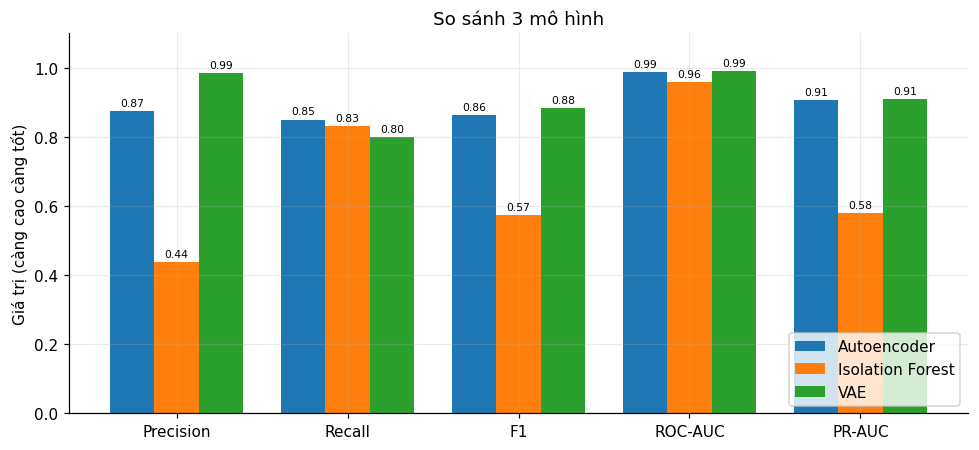

In [5]:
metrics = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
x = np.arange(len(metrics)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (m, title) in enumerate(MODELS.items()):
    v = TABLE.loc[title, metrics].astype(float).values
    bars = ax.bar(x + (i - 1) * w, v, w, label=title, color=COLORS[m])
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_xticks(x, metrics); ax.set_ylim(0, 1.1); ax.set_ylabel("Giá trị (càng cao càng tốt)")
ax.legend(loc="lower right"); ax.set_title("So sánh 3 mô hình")
fig.tight_layout(); fig.savefig("so_sanh_3_mo_hinh.png", dpi=150); plt.show()

## 5. Đường ROC và Precision–Recall của một thiết bị

Mỗi thiết bị có mô hình riêng nên điểm số không gộp được giữa các thiết bị. Ở đây vẽ cho thiết bị `DEV_PLOT` (đổi ở mục 1), gộp mọi loại tấn công.
- **ROC**: đường càng sát góc trên bên trái càng tốt.
- **PR** (tỷ lệ tấn công 5%): đường càng sát góc trên bên phải càng tốt. Đường ngang 0,05 là mức đoán bừa.

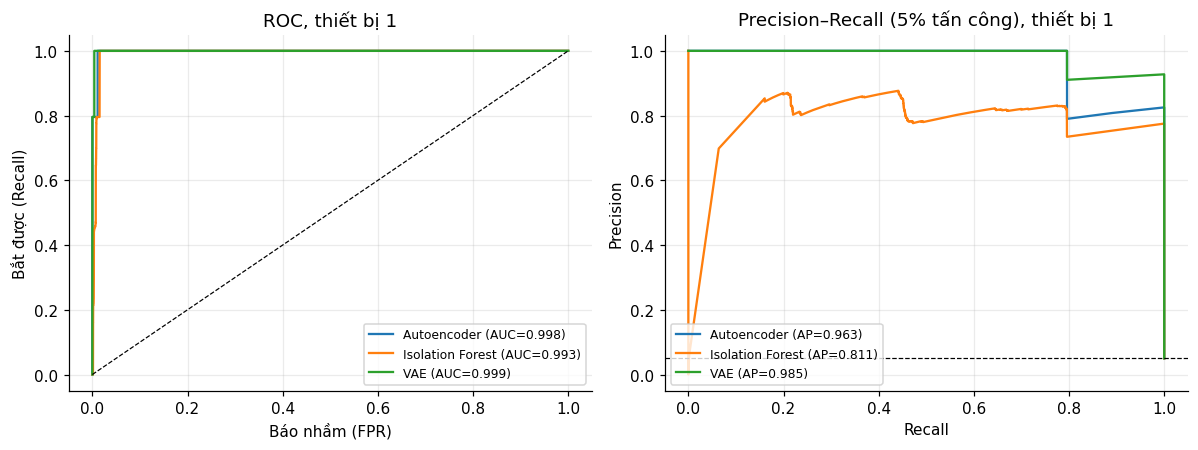

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
for m, title in MODELS.items():
    kind, split, s = load_scores(m, DEV_PLOT); role = make_roles(kind, split)
    sb, sa = s[role == "b_test"], s[role == "a_test"]
    y = np.r_[np.zeros(len(sb)), np.ones(len(sa))]; sc = np.r_[sb, sa]
    w = np.r_[np.full(len(sb), (1 - PI) / len(sb)), np.full(len(sa), PI / len(sa))]
    fpr, tpr, _ = roc_curve(y, sc)
    pr, rc, _ = precision_recall_curve(y, sc, sample_weight=w)
    a1.plot(fpr, tpr, color=COLORS[m], label=f"{title} (AUC={roc_auc_score(y, sc):.3f})")
    a2.plot(rc, pr, color=COLORS[m], label=f"{title} (AP={average_precision_score(y, sc, sample_weight=w):.3f})")
a1.plot([0, 1], [0, 1], "k--", lw=0.8); a1.set_xlabel("Báo nhầm (FPR)"); a1.set_ylabel("Bắt được (Recall)"); a1.set_title(f"ROC, thiết bị {DEV_PLOT}")
a2.axhline(PI, color="k", ls="--", lw=0.8); a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title(f"Precision–Recall (5% tấn công), thiết bị {DEV_PLOT}")
a1.legend(fontsize=8, loc="lower right"); a2.legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(f"roc_pr_dev{DEV_PLOT}.png", dpi=150); plt.show()

## 6. Phân phối lỗi tái tạo giữa benign và tấn công, có đánh dấu ngưỡng (task 2)

Mỗi hàng là một thiết bị, mỗi cột là một mô hình. Ba nhóm dòng (đều thuộc phần test):
- **benign test**: lưu lượng bình thường
- **tấn công khác**: 8 loại dễ bắt (mirai, gafgyt combo/junk/scan)
- **tcp/udp**: `gafgyt_tcp` và `gafgyt_udp`, hai loại khó bắt

Vạch **đỏ** là ngưỡng F1 tối ưu, vạch **xám** là ngưỡng percentile 99. Dòng nào có điểm nằm **bên phải vạch** thì bị báo là tấn công.
Với AE/VAE, điểm là lỗi tái tạo nên vẽ theo thang log10. Với Isolation Forest, điểm nằm trong khoảng 0 đến 1 nên vẽ thang thường.

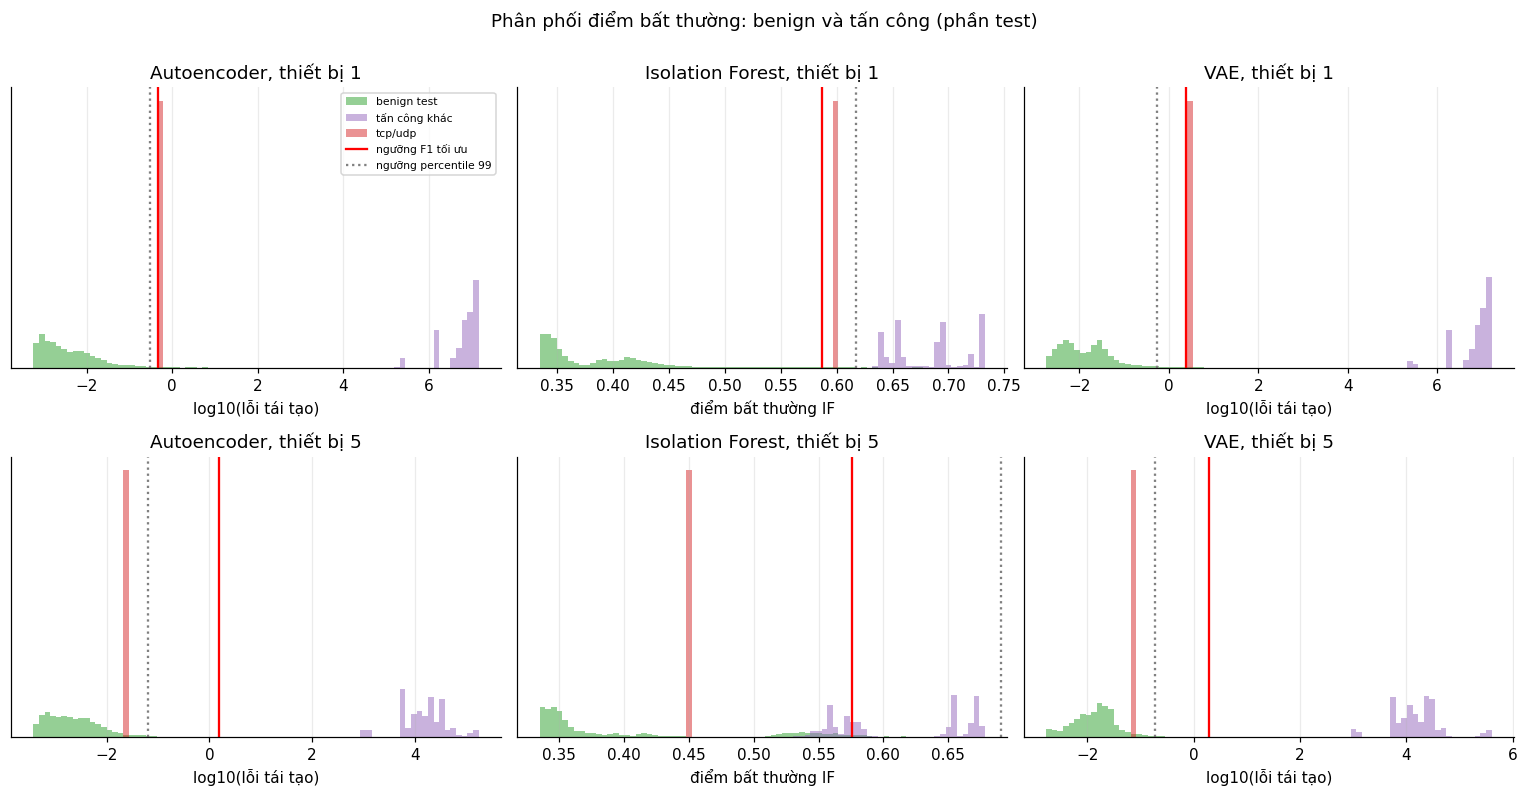

In [7]:
DEV_DIST = [d for d in [1, 5] if find(f"ae_dev{d}.npz")]   # đổi [1, 5] để xem thiết bị khác
CT = {m: pd.read_csv(find(f"{m}_chi_tiet.csv")) for m in MODELS}   # chi tiết từng (thiết bị, quy tắc, loại): ngưỡng, số dòng, số dòng bị báo

def get_thr(m, d, rule):
    t = CT[m]
    return float(t[(t.device_id == d) & (t.rule == rule)].thr.iloc[0])

rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(DEV_DIST), len(MODELS), figsize=(14, 3.6 * len(DEV_DIST)), squeeze=False)
for i, d in enumerate(DEV_DIST):
    for j, (m, title) in enumerate(MODELS.items()):
        ax = axes[i, j]
        kind, split, s = load_scores(m, d); role = make_roles(kind, split)
        is_tu = np.isin(kind, TCP_UDP)
        groups = {"benign test": role == "b_test",
                  "tấn công khác": (role == "a_test") & ~is_tu,
                  "tcp/udp": (role == "a_test") & is_tu}
        use_log = m != "iforest"
        tf = (lambda v: np.log10(np.maximum(v, 1e-12))) if use_log else (lambda v: v)
        vals = {}
        for name, mk in groups.items():
            v = s[mk]
            if len(v) > 200_000:
                v = rng.choice(v, 200_000, replace=False)       # lấy mẫu cho nhanh, hình dạng phân phối không đổi
            if len(v):
                vals[name] = tf(v)
        allv = np.concatenate(list(vals.values()))
        bins = np.linspace(*np.percentile(allv, [0.2, 99.8]), 80)     # bỏ 0,2% điểm cực trị ở hai đầu cho trục dễ nhìn
        for (name, v), col in zip(vals.items(), ["tab:green", "tab:purple", "tab:red"]):
            ax.hist(v, bins, alpha=0.5, density=True, label=name, color=col)
        ax.axvline(tf(get_thr(m, d, RULE)), color="red", lw=1.5, label="ngưỡng F1 tối ưu")
        ax.axvline(tf(get_thr(m, d, RULE_FAIR)), color="gray", ls=":", lw=1.5, label="ngưỡng percentile 99")
        ax.set_title(f"{title}, thiết bị {d}")
        ax.set_xlabel("log10(lỗi tái tạo)" if use_log else "điểm bất thường IF")
        ax.set_yticks([])
axes[0, 0].legend(fontsize=7)
fig.suptitle("Phân phối điểm bất thường: benign và tấn công (phần test)", y=1.0)
fig.tight_layout(); fig.savefig("phan_phoi_loi_tai_tao.png", dpi=150); plt.show()

**Cách đọc:** nhóm "tấn công khác" nằm xa hẳn về bên phải benign nên mọi ngưỡng đều bắt được.
Nhóm tcp/udp nằm **sát benign**: nếu vạch ngưỡng nằm bên trái cụm tcp/udp thì bắt hết, nằm bên phải thì bỏ sót hết.
Vì vậy ở bảng mục 8, tỷ lệ bắt tcp/udp của từng thiết bị gần như chỉ có 0% hoặc 100%.

## 7. Confusion matrix 

Đếm trên phần test, gộp 9 thiết bị, theo ngưỡng F1 tối ưu:

| | Dự đoán benign | Dự đoán tấn công |
| --- | --- | --- |
| **Thật benign** | TN (đúng) | **FP** (báo nhầm) |
| **Thật tấn công** | **FN** (bỏ sót) | TP (bắt được) |

Mỗi ô ghi **tỷ lệ theo hàng** (so với số dòng thật của lớp đó) và số dòng trong ngoặc.
Lưu ý: ở đây tỷ lệ bắt được tính trên **tổng số dòng**, nên khác Recall ở mục 2 (trung bình các loại tấn công). Loại nhiều dòng như tcp/udp sẽ kéo con số này xuống.

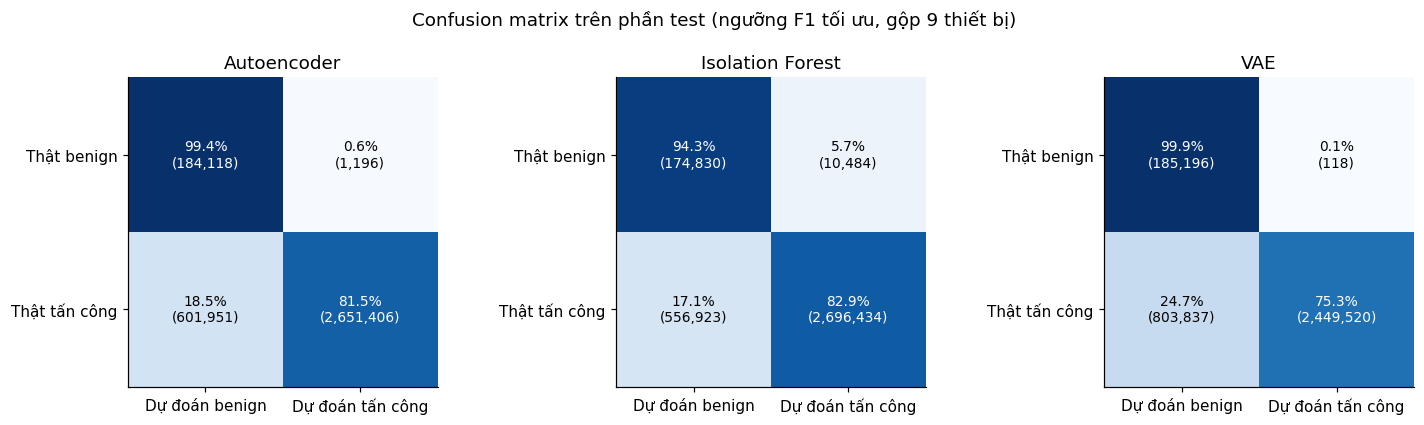

,TN,FP,FN,TP,Báo nhầm (FP/benign),Bắt được (TP/tấn công)
Mô hình,,,,,,
Autoencoder,"184,118","1,196","601,951","2,651,406",0.65%,81.5%
Isolation Forest,"174,830","10,484","556,923","2,696,434",5.66%,82.9%
VAE,"185,196",118,"803,837","2,449,520",0.06%,75.3%


In [8]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(13.5, 3.9))
CM = []
for ax, (m, title) in zip(axes, MODELS.items()):
    t = CT[m][CT[m].rule == RULE]
    b, a = t[t.kind == "benign"], t[t.kind != "benign"]
    TN, FP = int((b.n - b.n_flag).sum()), int(b.n_flag.sum())
    FN, TP = int((a.n - a.n_flag).sum()), int(a.n_flag.sum())
    cm = np.array([[TN, FP], [FN, TP]]); rate = cm / cm.sum(1, keepdims=True)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f"{rate[r, c]:.1%}\n({v:,})", ha="center", va="center", fontsize=9,
                color="white" if rate[r, c] > 0.5 else "black")
    ax.set_xticks([0, 1], ["Dự đoán benign", "Dự đoán tấn công"]); ax.set_yticks([0, 1], ["Thật benign", "Thật tấn công"])
    ax.grid(False); ax.set_title(title)
    CM.append({"Mô hình": title, "TN": TN, "FP": FP, "FN": FN, "TP": TP,
               "Báo nhầm (FP/benign)": FP / (TN + FP), "Bắt được (TP/tấn công)": TP / (TP + FN)})
fig.suptitle("Confusion matrix trên phần test (ngưỡng F1 tối ưu, gộp 9 thiết bị)")
fig.tight_layout(); fig.savefig("confusion_matrix.png", dpi=150); plt.show()

CM = pd.DataFrame(CM).set_index("Mô hình")
CM.to_csv("confusion_matrix.csv")
display(CM.style.format({"TN": "{:,}", "FP": "{:,}", "FN": "{:,}", "TP": "{:,}",
                         "Báo nhầm (FP/benign)": "{:.2%}", "Bắt được (TP/tấn công)": "{:.1%}"}))

Dữ liệu test có tấn công nhiều hơn benign rất nhiều, khác với thực tế. Bảng dưới quy về một tình huống dễ hình dung:
**cứ 10.000 dòng lưu lượng thì có 500 dòng tấn công (5%)**, mỗi mô hình sẽ cho kết quả thế nào.

In [9]:
E = pd.DataFrame({
    "Bắt được (TP)": 500 * CM["Bắt được (TP/tấn công)"],
    "Bỏ sót (FN)": 500 * (1 - CM["Bắt được (TP/tấn công)"]),
    "Báo nhầm (FP)": 9500 * CM["Báo nhầm (FP/benign)"],
    "Benign đúng (TN)": 9500 * (1 - CM["Báo nhầm (FP/benign)"]),
}).round(0).astype(int)
E["Tổng cảnh báo"] = E["Bắt được (TP)"] + E["Báo nhầm (FP)"]
E["Cảnh báo sai / tổng cảnh báo"] = E["Báo nhầm (FP)"] / E["Tổng cảnh báo"]
display(E.style.format({"Cảnh báo sai / tổng cảnh báo": "{:.1%}"}).set_caption("Ước tính trên 10.000 dòng, 5% tấn công"))

,Bắt được (TP),Bỏ sót (FN),Báo nhầm (FP),Benign đúng (TN),Tổng cảnh báo,Cảnh báo sai / tổng cảnh báo
Mô hình,,,,,,
Autoencoder,407,93,61,9439,468,13.0%
Isolation Forest,414,86,537,8963,951,56.5%
VAE,376,124,6,9494,382,1.6%


## 8. Phân tích lỗi theo thiết bị và loại tấn công 

### 8.1 Tỷ lệ bắt được theo thiết bị × loại tấn công

Mỗi ô là tỷ lệ bắt được (ngưỡng F1 tối ưu). Ô xám là thiết bị không có loại tấn công đó.

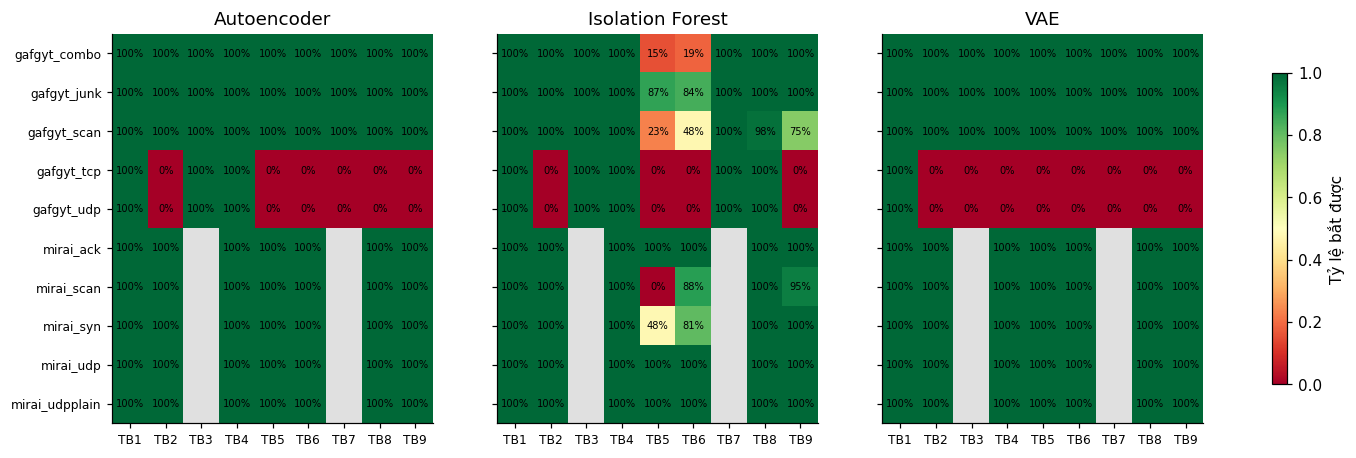

In [10]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 4.6), sharey=True)
cmap = plt.get_cmap("RdYlGn").copy(); cmap.set_bad("#e0e0e0")
for ax, (m, title) in zip(axes, MODELS.items()):
    t = CT[m][(CT[m].rule == RULE) & (CT[m].kind != "benign")]
    H = t.pivot_table(index="kind", columns="device_id", values="row_rate")
    im = ax.imshow(np.ma.masked_invalid(H.values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(H.shape[1]), [f"TB{c}" for c in H.columns], fontsize=8)
    ax.set_yticks(range(H.shape[0]), H.index, fontsize=8)
    for (r, c), v in np.ndenumerate(H.values):
        if not np.isnan(v):
            ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=6.5)
    ax.grid(False); ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8, label="Tỷ lệ bắt được")
fig.savefig("ban_do_nhiet_3_mo_hinh.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.2 Recall theo loại tấn công (gộp 9 thiết bị) và các cặp bị bỏ sót

In [11]:
cols = {}
for m, title in MODELS.items():
    t = pd.read_csv(find(f"{m}_theo_loai.csv")).set_index("Loại")
    cols[title] = pd.to_numeric(t["F1 tối ưu (dùng nhãn val)"], errors="coerce")
K = pd.DataFrame(cols)
ben = K.loc[["benign"]]; K = K.drop(index="benign")
display(K.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("Recall theo loại tấn công (ngưỡng F1 tối ưu)"))

miss = []
for m, title in MODELS.items():
    t = CT[m][(CT[m].rule == RULE) & (CT[m].kind != "benign")]
    for _, r in t[t.row_rate < 0.5].iterrows():
        miss.append({"Mô hình": title, "Thiết bị": int(r.device_id), "Loại": r.kind, "Bắt được": r.row_rate})
MISS = pd.DataFrame(miss)
if len(MISS):
    S = MISS.groupby(["Mô hình", "Loại"]).agg(**{"Số thiết bị bỏ sót": ("Thiết bị", "count"),
                                                  "Thiết bị": ("Thiết bị", lambda x: ", ".join(map(str, sorted(x))))})
    display(S.style.set_caption("Các (loại tấn công, thiết bị) bị bắt dưới 50%"))

,Autoencoder,Isolation Forest,VAE
Loại,,,
gafgyt_combo,100.0%,80.8%,100.0%
gafgyt_junk,100.0%,96.7%,100.0%
gafgyt_scan,100.0%,82.3%,100.0%
gafgyt_tcp,33.3%,55.0%,10.7%
gafgyt_udp,33.4%,56.0%,11.2%
mirai_ack,100.0%,100.0%,100.0%
mirai_scan,100.0%,79.4%,100.0%
mirai_syn,100.0%,93.6%,100.0%
mirai_udp,100.0%,100.0%,100.0%


### 8.3 Báo nhầm theo thiết bị

Tỷ lệ benign test bị báo nhầm của từng thiết bị. Thiết bị nào báo nhầm cao thì hành vi bình thường của nó thay đổi theo thời gian (benign test khác benign val) hoặc khó mô hình hóa.

In [12]:
F = pd.DataFrame({title: CT[m][(CT[m].rule == RULE) & (CT[m].kind == "benign")].set_index("device_id").row_rate
                  for m, title in MODELS.items()})
F.index.name = "Thiết bị"
display(F.T.style.format("{:.2%}").background_gradient(cmap="Reds", axis=None, vmin=0, vmax=0.1)
        .set_caption("Tỷ lệ báo nhầm theo thiết bị (ngưỡng F1 tối ưu)"))

Thiết bị,1,2,3,4,5,6,7,8,9
Autoencoder,1.11%,0.05%,1.68%,1.34%,0.00%,0.01%,0.01%,0.02%,0.00%
Isolation Forest,1.77%,2.77%,3.05%,5.76%,5.63%,10.11%,2.85%,8.37%,0.46%
VAE,0.61%,0.05%,0.00%,0.01%,0.01%,0.01%,0.01%,0.03%,0.00%


### 8.4 Vì sao tcp/udp bị bỏ sót?

Ba bằng chứng:
1. **So ở cùng mức báo nhầm** (cùng một quy tắc percentile): mô hình nào bắt tcp/udp nhiều hơn khi cùng chấp nhận khoảng 5% hoặc 10% báo nhầm.
2. **ROC-AUC của tcp/udp theo thiết bị**: điểm số có tách được tcp/udp khỏi benign không, bất kể ngưỡng.
3. Biểu đồ ở mục 6: tcp/udp nằm sát benign.

In [13]:
rows = []
for m, title in MODELS.items():
    t = pd.read_csv(find(f"{m}_tong_hop.csv")).set_index("Quy tắc ngưỡng")
    for lab in ["percentile 99", "percentile 95", "percentile 90", "F1 tối ưu (dùng nhãn val)"]:
        rows.append({"Quy tắc": lab, "Mô hình": title, "Báo nhầm": t.loc[lab, "Báo nhầm"], "Bắt tcp/udp": t.loc[lab, "Bắt tcp/udp"]})
EQ = pd.DataFrame(rows).pivot(index="Quy tắc", columns="Mô hình", values=["Báo nhầm", "Bắt tcp/udp"])
display(EQ.style.format("{:.1%}").set_caption("Bắt tcp/udp ở cùng quy tắc ngưỡng (mức báo nhầm tương đương)"))

A = AUCD[AUCD.kind.isin(TCP_UDP)].groupby(["model", "device_id"]).roc_auc.mean().unstack()
A.index = A.index.map(MODELS); A.columns.name = "Thiết bị"
display(A.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1, axis=None)
        .set_caption("ROC-AUC của tcp/udp theo thiết bị (0,5 = không tách được, 1 = tách hoàn toàn)"))

Thiết bị,1,2,3,4,5,6,7,8,9
model,,,,,,,,,
Autoencoder,0.989,0.860,0.986,0.987,0.954,0.865,0.965,0.959,0.957
Isolation Forest,0.985,0.923,0.974,0.950,0.747,0.674,0.974,0.918,0.981
VAE,0.996,0.933,0.968,0.969,0.951,0.870,0.970,0.935,0.993


**Giải thích (đối chiếu với số liệu 3 notebook mô hình):**
- Với AE và VAE, 8 loại tấn công khác bị tách ra rất xa benign. Ngưỡng F1 tối ưu vì thế nằm sát phía trên benign để gần như không báo nhầm, và tcp/udp, vốn chỉ cao hơn benign một chút, rơi xuống dưới ngưỡng.
- Isolation Forest tách các loại dễ kém hơn, nên ngưỡng tối ưu phải hạ thấp (báo nhầm khoảng 5,7%). Ngưỡng thấp này vô tình quét luôn tcp/udp, nên Recall tcp/udp của IF cao hơn **không phải vì IF nhận ra tcp/udp tốt hơn**.
- Ở cùng mức báo nhầm khoảng 5% (percentile 95), AE bắt tcp/udp 55,6%, còn IF 44,9% và VAE 45,1%.
- Về mặt dữ liệu, một giả thuyết là tcp/udp flood của Gafgyt có thống kê lưu lượng gần với lưu lượng bình thường hơn các kiểu tấn công khác (cần kiểm tra thêm bằng EDA).
- **Hướng cải thiện:** chọn ngưỡng riêng cho tcp/udp hoặc cho từng thiết bị, hoặc dùng bỏ phiếu theo cửa sổ (mục V.7 của các notebook mô hình).

## 9. Chi phí huấn luyện

In [14]:
rows = []
for m, title in MODELS.items():
    t = pd.read_csv(find(f"{m}_huan_luyen.csv"))
    fit = (t["fit_seconds"] if "fit_seconds" in t else t["seconds"]).sum()   # IF lưu fit_seconds, AE/VAE lưu seconds
    rows.append({"Mô hình": title, "Tổng giây huấn luyện (9 thiết bị)": round(float(fit), 1)})
COST = pd.DataFrame(rows).set_index("Mô hình")
COST

,Tổng giây huấn luyện (9 thiết bị)
Mô hình,
Autoencoder,482.1
Isolation Forest,4.7
VAE,471.2


## 10. Kết luận

In [15]:
best = lambda c, low=False: TABLE[c].astype(float).idxmin() if low else TABLE[c].astype(float).idxmax()
display(Markdown(f"""
- **F1 cao nhất:** {best('F1')} (F1 = {TABLE.loc[best('F1'), 'F1']:.3f})
- **Precision cao nhất / báo nhầm thấp nhất:** {best('Precision')} / {best('Báo nhầm (FPR)', low=True)}
- **Recall cao nhất:** {best('Recall')}
- **ROC-AUC cao nhất:** {best('ROC-AUC')} ({TABLE.loc[best('ROC-AUC'), 'ROC-AUC']:.3f}); **PR-AUC cao nhất:** {best('PR-AUC')} ({TABLE.loc[best('PR-AUC'), 'PR-AUC']:.3f})
- **Bắt tcp/udp tốt nhất (ở ngưỡng F1 tối ưu):** {best('Recall tcp/udp')} ({TABLE.loc[best('Recall tcp/udp'), 'Recall tcp/udp']:.1%})
- **Huấn luyện nhanh nhất:** {COST.iloc[:, 0].idxmin()}
"""))


- **F1 cao nhất:** VAE (F1 = 0.883)
- **Precision cao nhất / báo nhầm thấp nhất:** VAE / VAE
- **Recall cao nhất:** Autoencoder
- **ROC-AUC cao nhất:** VAE (0.990); **PR-AUC cao nhất:** VAE (0.910)
- **Bắt tcp/udp tốt nhất (ở ngưỡng F1 tối ưu):** Isolation Forest (55.5%)
- **Huấn luyện nhanh nhất:** Isolation Forest


### Nhận xét (theo số liệu trong 3 notebook mô hình, ngưỡng F1 tối ưu)

| | Autoencoder | Isolation Forest | VAE |
| --- | --- | --- | --- |
| Precision | 87,4% | 43,6% | **98,5%** |
| Recall | **85,0%** | 83,2% | 80,0% |
| F1 | 0,862 | 0,573 | **0,883** |
| Báo nhầm | 0,65% | 5,66% | **0,1%** |
| Recall tcp/udp | 33,3% | **55,5%** | 11,0% |

1. **VAE có F1 cao nhất và gần như không báo nhầm**, nhưng bỏ sót gần hết tcp/udp.
2. **Autoencoder cân bằng nhất**: không chỉ số nào đứng cuối, F1 gần bằng VAE, báo nhầm dưới 1%, bắt tcp/udp gấp 3 lần VAE.
3. **Isolation Forest** là baseline nhanh (khoảng 0,5 giây mỗi thiết bị), nhưng báo nhầm cao và phụ thuộc nhiều vào ngưỡng (F1 chỉ 0,302 với percentile 99).
4. Điểm yếu chung là `gafgyt_tcp`/`gafgyt_udp`, do vị trí ngưỡng (mục 8.4).

**Hạn chế:** ngưỡng F1 tối ưu dùng nhãn tấn công của nửa val (bán giám sát); val và test của tấn công lấy từ cùng file nên chỉ chứng minh bắt được loại tấn công **đã thấy**; kết quả là một lần chạy với một seed.

**File đã lưu:** `bang_so_sanh_3_mo_hinh.csv`, `so_sanh_3_mo_hinh.png`, `roc_pr_devN.png`, `phan_phoi_loi_tai_tao.png`, `confusion_matrix.png`, `confusion_matrix.csv`, `ban_do_nhiet_3_mo_hinh.png`.